# INCREMENT — Uplift Lab

Исполненный разбор проекта: эксперимент → признаки → отложенная оценка → бизнес-решение.
Полная пересборка: из корня проекта выполнить python run.py. Этот ноутбук читает полученные артефакты и независимо пересчитывает основной эффект.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
# Works when launched from either project root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / 'run.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
R = json.loads((ROOT / 'reports/results.json').read_text(encoding='utf-8'))
print('Rows:', R['quality']['rows'])
print('Split:', R['quality']['split_counts'])
print('Versions:', R['versions'])

Rows: 64000
Split: {'train': 38400, 'test': 12800, 'validation': 12800}
Versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.5.2', 'scipy': '1.14.1', 'duckdb': '1.1.3', 'matplotlib': '3.9.2'}


## 1. О чём спрашиваем бизнес
Кому отправить мужское или женское письмо при ограниченном охвате? Основной исход — покупка за две недели. Главная проверка: персональный выбор письма против случайной рассылки мужского письма при охвате 20%.

In [2]:
metrics = pd.read_csv(ROOT/'reports/tables/experiment_metrics.csv')
print(metrics.to_string(index=False))
effects = pd.read_csv(ROOT/'reports/tables/experiment_effects.csv')
print('\nConversion contrasts:')
print(effects.query("outcome == 'conversion'")[['arm','estimate','low','high','pvalue_holm']].to_string(index=False))

      segment  customers  purchases  conversion_rate  visit_rate  revenue_per_customer  total_revenue
  Mens E-Mail      21307      267.0         0.012531    0.182757              1.422617       30311.69
    No E-Mail      21306      122.0         0.005726    0.106167              0.652789       13908.33
Womens E-Mail      21387      189.0         0.008837    0.151400              1.077202       23038.11

Conversion contrasts:
          arm  estimate      low     high  pvalue_holm
  Mens E-Mail  0.006805 0.005000 0.008610 5.884837e-13
Womens E-Mail  0.003111 0.001499 0.004724 3.116139e-04


## 2. Разделяем эксперимент и ML
Назначение писем случайное, вероятность 1/3. Разбиение 60/20/20 стратифицировано только по назначению. Модель выбрана на валидации, решения записаны до оценки теста. Совпадающие строки не удаляем: customer_id нет. Идентификатор source_row — лишь номер строки CSV.

In [3]:
splits = pd.read_csv(ROOT/'data/processed/splits.csv')
print(splits.groupby('split').source_row.agg(['count','nunique']))
print('Unique across all splits:', splits.source_row.is_unique)
print('Selection lock:')
print(json.dumps(R['selection'],ensure_ascii=False,indent=2))

            count  nunique
split                     
test        12800    12800
train       38400    38400
validation  12800    12800
Unique across all splits: True
Selection lock:
{
  "seed": 42,
  "primary_outcome": "conversion",
  "primary_coverage": 0.2,
  "selected_models": {
    "uplift": "logit_0.1",
    "multiarm": "logit_0.1"
  },
  "candidates": [
    "logit_0.1",
    "logit_1",
    "boost"
  ],
  "selection_metric": "validation AIPW incremental conversions at 20% contacts",
  "primary_contrast": "multiarm minus random_mens",
  "propensity": [
    0.3333333333333333,
    0.3333333333333333,
    0.3333333333333333
  ],
  "splits_sha256": "411533ff17269ec30742a6bde4fbdd4eb4464381f45c0cc8db4842d100399c82"
}


## 3. Признаки и утечки
Используем только историю до воздействия. Пол клиента неизвестен: mens/womens означают прежние покупки соответствующего ассортимента. visit, conversion и spend измерены после письма и исключены из X.

In [4]:
from src.core import FEATURES
print('Pretreatment features:', FEATURES)
selection = pd.read_csv(ROOT/'reports/tables/model_selection.csv')
print(selection.to_string(index=False))

Pretreatment features: ['recency', 'log_history', 'mens', 'womens', 'newbie', 'zip_code', 'channel']
    model     mode  coverage  estimate       se       low     high
logit_0.1   uplift       0.2  0.001228 0.001140 -0.001007 0.003462
logit_0.1 multiarm       0.2  0.000776 0.001042 -0.001266 0.002819
  logit_1   uplift       0.2  0.001228 0.001140 -0.001008 0.003463
  logit_1 multiarm       0.2 -0.000164 0.001043 -0.002208 0.001880
    boost   uplift       0.2  0.000472 0.001117 -0.001718 0.002661
    boost multiarm       0.2  0.000491 0.001164 -0.001789 0.002772


## 4. Модель покупки и uplift
T-learner обучает отдельную модель P(покупка | X, группа). Обычная response-стратегия ранжирует по прогнозу с мужским письмом; binary uplift — по разнице с контролем. Эти две стратегии используют одинаковые модели, различается именно ранжирование. Multi-arm выбирает письмо с наибольшей предсказанной разницей.

In [5]:
h = pd.read_csv(ROOT/'data/processed/holdout_predictions.csv')
print(h[['binary_p_0','binary_p_1','multi_p_0','multi_p_1','multi_p_2']].head().round(5))
uplift = h[['multi_p_1','multi_p_2']].to_numpy()-h[['multi_p_0']].to_numpy()
print('Predicted uplift quantiles:', np.quantile(uplift.max(axis=1),[0,.25,.5,.75,1]))

   binary_p_0  binary_p_1  multi_p_0  multi_p_1  multi_p_2
0     0.00373     0.00925    0.00373    0.00925    0.00391
1     0.00549     0.00961    0.00549    0.00961    0.00794
2     0.00340     0.00641    0.00340    0.00641    0.00789
3     0.00922     0.01279    0.00922    0.01279    0.01500
4     0.00876     0.01475    0.00876    0.01475    0.00741
Predicted uplift quantiles: [-0.00258714  0.0044437   0.00596792  0.00818065  0.02557894]


## 5. Оценка стратегии через AIPW
Для каждого действия score_a = mu_a(X) + I(A=a)/e_a * (Y-mu_a(X)).
Затем сравниваем ожидаемый исход стратегии с действием «без письма». Модель mu обучена на train+validation, а не на тесте. Известная вероятность воздействия защищает оценку от неверной outcome-модели. Значения score не ограничиваем диапазоном [0,1].

In [6]:
from src.core import arm_scores, policy_weights, policy_scores, summarize
mu = h[['mu_0','mu_1','mu_2']].to_numpy()
phi = arm_scores(h.conversion.to_numpy(),h.action.to_numpy(),mu)
score = uplift.max(axis=1)
best_email = uplift.argmax(axis=1)+1
personal = policy_weights(score,.2,best_email)
random = policy_weights(np.zeros(len(h)),.2,1,random=True)
personal_gain = policy_scores(personal,phi)-phi[:,0]
random_gain = policy_scores(random,phi)-phi[:,0]
comparison = summarize(personal_gain-random_gain,scale=10000)
print('Additional purchases / 10,000, personalized minus random:')
print(comparison)
print('Reproduces saved result:', np.isclose(comparison['estimate'],R['primary']['estimate']*10000))

Additional purchases / 10,000, personalized minus random:
{'estimate': -2.330263446285004, 'se': 9.017424290775349, 'low': -20.004415056204685, 'high': 15.343888163634679}
Reproduces saved result: True


## 6. Что можно утверждать
Если интервал парной разницы содержит ноль, преимущество этой персонализации не установлено. Это не доказывает равенство стратегий. Отдельные интервалы стратегий нельзя использовать вместо парного сравнения. Разные охваты на одном тесте — исследовательский анализ, не независимые подтверждения.

In [7]:
policies = pd.read_csv(ROOT/'reports/tables/test_policies.csv')
p20 = policies[np.isclose(policies.coverage,.2)].copy()
for col in ['estimate','low','high']:
    p20[col] *= 10000
print(p20[['label','estimate','low','high']].to_string(index=False))

                    label  estimate       low      high
Случайно / мужское письмо 17.201485  8.545482 25.857487
      Вероятность покупки 17.336076 -7.996497 42.668649
         Недавние покупки 28.955131  2.852007 55.058255
  Uplift / мужское письмо 17.499017 -1.854675 36.852709
    Uplift / выбор письма 14.871221 -5.010299 34.752742


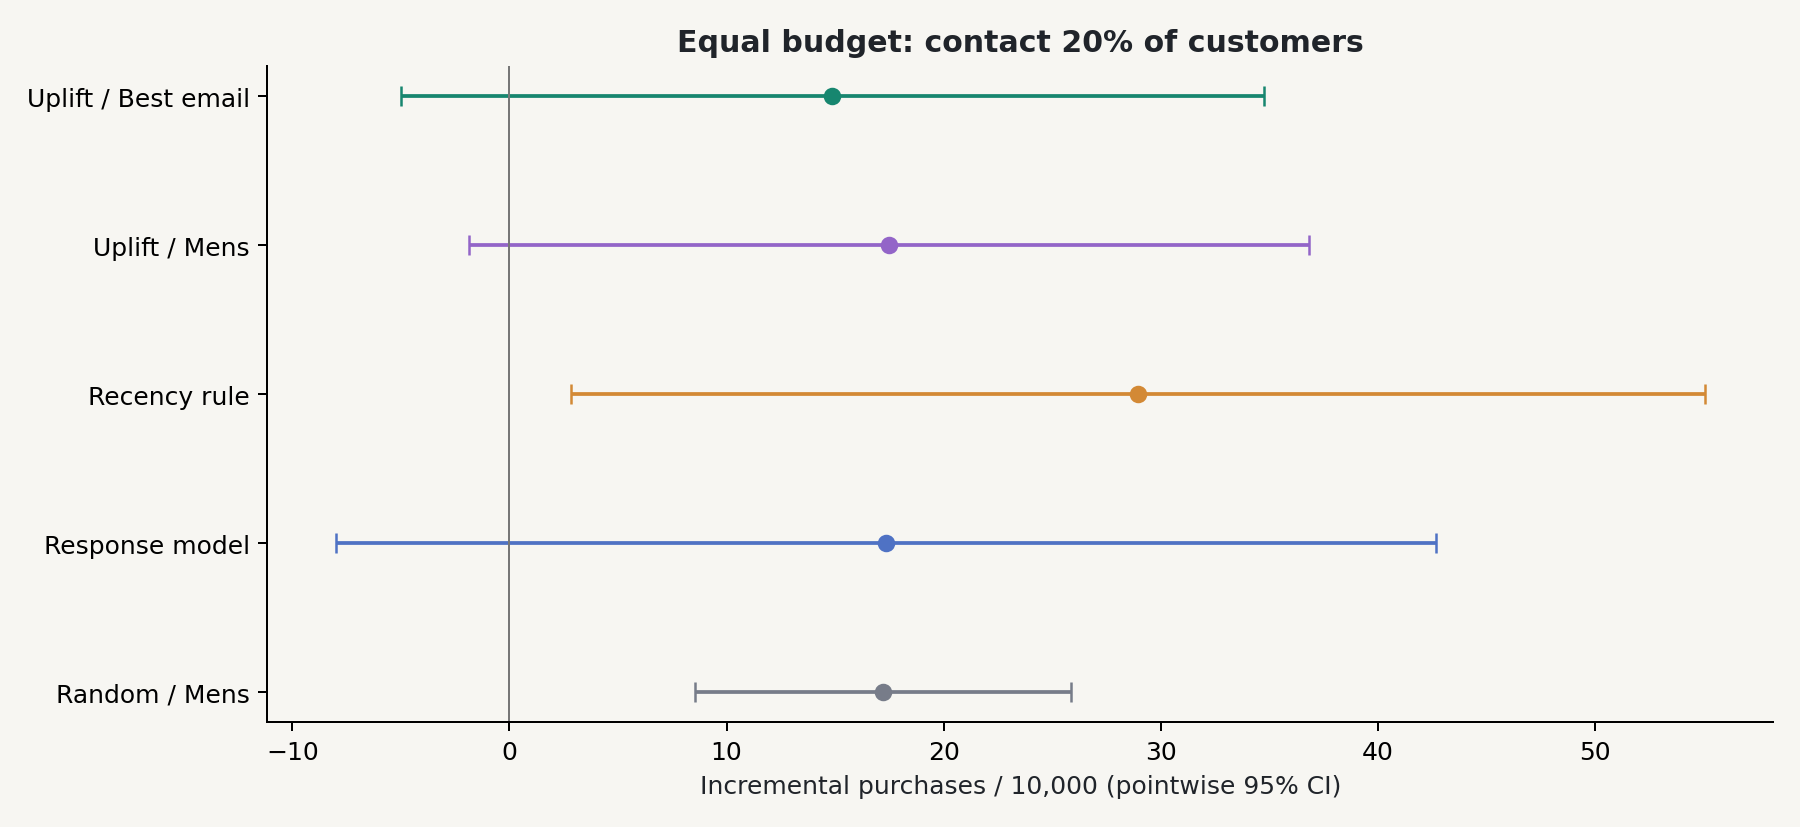

In [8]:
# Static figure generated by python run.py

## 7. Экономика сценария
Доп. прибыль = N × доп. вероятность покупки × маржа − N × охват × стоимость контакта. Маржа и стоимость придуманы для сценария, а не взяты из датасета. Интервалы условны на модели, не учитывают обучение и неопределённость переноса на новый бизнес.

In [9]:
N, margin, cost, coverage = 10000, 25, .02, .2
gain = summarize(personal_gain)
expense = N*coverage*cost
print('Contacts:',int(N*coverage),'Cost:',expense)
print('Scenario incremental contribution:', N*gain['estimate']*margin-expense)
print('Scenario 95% CI:',(N*gain['low']*margin-expense,N*gain['high']*margin-expense))

Contacts: 2000 Cost: 40.0
Scenario incremental contribution: 331.780530270031
Scenario 95% CI: (-165.25748135353768, 828.8185418935998)


## 8. Следующий бизнес-шаг
Зафиксировать сегментацию и охват до новой кампании, затем провести свежий рандомизированный тест стратегий. Для долгосрочного решения измерять покупки, маржу, отписки и повторные контакты. Подробные ограничения — reports/REPORT_RU.md; калькулятор — reports/dashboard.html.